# Regression with `scikitlearn` II

**OBJECTIVES**

- Fill in missing values with `SimpleImputer`
- Build polynomial regression models using `PolynomialFeatures` and `Pipeline`
- Use train/test split to train and evaluate a model
- Use cross validation to further validate a models performance
- Use `GridSearchCV` to search for ideal parameters

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Returning to the housing problem

Below we reload the housing data and display the basic info on the data.

In [2]:
housing = pd.read_csv('data/housing.csv')
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


### Filling missing values with `SimpleImputer`

We discussed filling in missing values using basic statistics -- with `scikitlearn` the `SimpleImputer` can help.  We use this in a similar way to what we did with the `OneHotEncoder` and `make_column_transformer`.

In [3]:
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

In [4]:
imputer = SimpleImputer()
ohe = OneHotEncoder(drop = 'first')

In [5]:
transformer = make_column_transformer((ohe, ['ocean_proximity']),
                                      (imputer, ['total_bedrooms']),
                                      remainder = 'passthrough',
                                     force_int_remainder_cols=False)

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

In [7]:
pipe = Pipeline([('transform', transformer), ('model', LinearRegression())])

In [8]:
X = housing.drop(columns = ['median_house_value'])
y = housing['median_house_value']

In [9]:
pipe.fit(X, y)

Pipeline(steps=[('transform',
                 ColumnTransformer(force_int_remainder_cols=False,
                                   remainder='passthrough',
                                   transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='first'),
                                                  ['ocean_proximity']),
                                                 ('simpleimputer',
                                                  SimpleImputer(),
                                                  ['total_bedrooms'])])),
                ('model', LinearRegression())])

In [10]:
pipe.score(X, y)

0.6454747751244776

### Adding polynomial features

In addition to learning a linear model, we can learn parameters for polynomial terms as well:

$$ \text{median house value} = \text{intercept} + \beta_0 \times \text{median income} + \beta_1 \times \text{median income}^2 $$

In [11]:
income = housing[['median_income']]

In [12]:
from sklearn.preprocessing import PolynomialFeatures

In [13]:
polyfeat = PolynomialFeatures(degree = 2, include_bias = False)

In [14]:
polyfeat.fit_transform(income)

array([[ 8.3252    , 69.30895504],
       [ 8.3014    , 68.91324196],
       [ 7.2574    , 52.66985476],
       ...,
       [ 1.7       ,  2.89      ],
       [ 1.8672    ,  3.48643584],
       [ 2.3886    ,  5.70540996]])

In [15]:
poly_features = polyfeat.fit_transform(income)
pd.DataFrame(poly_features, columns = polyfeat.get_feature_names_out()).head()

,median_income,median_income^2
0,8.3252,69.308955
1,8.3014,68.913242
2,7.2574,52.669855
3,5.6431,31.844578
4,3.8462,14.793254


In [16]:
quad_model = LinearRegression()

In [17]:
quad_model.fit(poly_features, y)

LinearRegression()

In [18]:
quad_model.coef_

array([53211.26540189, -1050.41892981])

In [19]:
quad_model.intercept_

20421.107102795853

$$\text{median house value} = 20,421 + 53,211 \times \text{median income} - 1,050 \times \text{median income}^2$$

In [20]:
quad_model.score(poly_features, y)

0.47802403432955454

### Fitting Higher Order Polynomials

Let's try a cubic model:

$$ \text{median house value} = \text{intercept} + \beta_0 \times \text{median income} + \beta_1 \times \text{median income}^2 +  \beta_2 \times \text{median income}^3$$

In [21]:
income.shape

(20640, 1)

In [22]:
y = housing['median_house_value']

In [23]:
polyfeat = PolynomialFeatures(degree = 3, include_bias = False)
# poly_features = polyfeat.fit_transform(income)
cubic_model = LinearRegression()
cubic_pipe = Pipeline([('transform', polyfeat), ('model', cubic_model)])
cubic_pipe.fit(income, y)

Pipeline(steps=[('transform', PolynomialFeatures(degree=3, include_bias=False)),
                ('model', LinearRegression())])

In [24]:
cubic_pipe.score(income, y)

0.4861953377905175

### Over vs Underfitting

![](images/under_vs_overfit.png)

The idea is that there is a "sweet spot" where the complexity of the model appropriately models the data without overfitting the noise.  There are two considerations here, the first is how to determine the right fit conceptually, then practically searching for the right model.

### Train vs. Test split

To gauge the fit of the model we can create a holdout set of the data called the "test" set.  We will show our models data and see how they do at predicting the test data they have not seen.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [27]:
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [28]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(15480, 9) (5160, 9) (15480,) (5160,)


#### A Smaller Example

Below a simple function is created and different complexities of models are fit to the data.

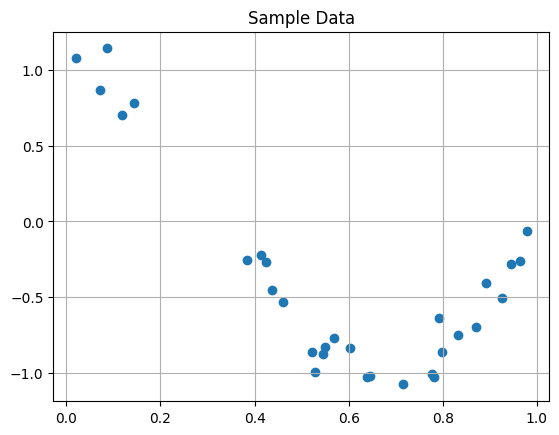

In [29]:
def true_fun(X):
    return np.cos(1.5 * np.pi * X)


np.random.seed(0)

n_samples = 30
degrees = [1, 4, 15]

X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1
X_train, X_test, y_train, y_test = train_test_split(X.reshape(-1, 1), y)
plt.scatter(X, y)
plt.title('Sample Data')
plt.grid();

In [30]:
train_errors = []
test_errors = []
models = []
for i in range(1, 15):
    poly = PolynomialFeatures(degree = i, include_bias = False)
    pipe = Pipeline([('poly', poly), ('model', LinearRegression())])
    pipe.fit(X_train, y_train)
    models.append(pipe)
    train_errors.append(np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))))
    test_errors.append(np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))))
    print(f'Degree {i}')
    print(f'Train RMSE: {np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))}')
    print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))}')
    print('===============')

Degree 1
Train RMSE: 0.4933993339578558
Test RMSE: 0.45596367595998893
Degree 2
Train RMSE: 0.15733785330321684
Test RMSE: 0.21528505530303044
Degree 3
Train RMSE: 0.10642965252275946
Test RMSE: 0.13406336563399365
Degree 4
Train RMSE: 0.10116509380816127
Test RMSE: 0.13544239465807384
Degree 5
Train RMSE: 0.10003253636250493
Test RMSE: 0.13064531512094124
Degree 6
Train RMSE: 0.09993121237569669
Test RMSE: 0.12998259443522397
Degree 7
Train RMSE: 0.0903014465709698
Test RMSE: 0.17139960730096027
Degree 8
Train RMSE: 0.09026500358777
Test RMSE: 0.1719636056918159
Degree 9
Train RMSE: 0.08887981772035766
Test RMSE: 0.170309109138568
Degree 10
Train RMSE: 0.08460807633545926
Test RMSE: 0.2197532831011238
Degree 11
Train RMSE: 0.0828017429452772
Test RMSE: 0.2581465993064075
Degree 12
Train RMSE: 0.08108378292776214
Test RMSE: 0.2810417078494075
Degree 13
Train RMSE: 0.05913868932517504
Test RMSE: 0.45395161492017627
Degree 14
Train RMSE: 0.05025772750980449
Test RMSE: 0.8244961673591034


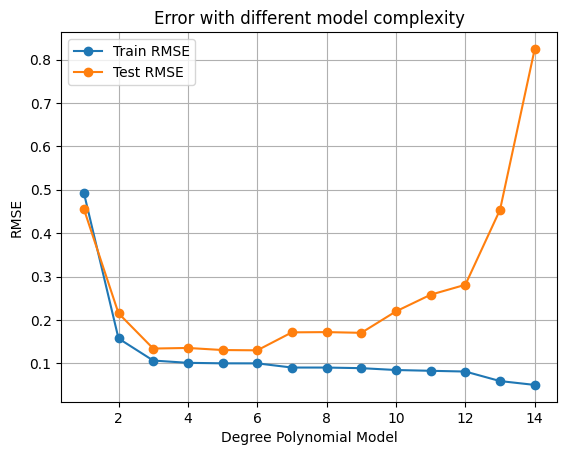

In [31]:
plt.plot(range(1,15), train_errors, '-o', label = 'Train RMSE')
plt.plot(range(1, 15), test_errors, '-o', label = 'Test RMSE')
plt.title('Error with different model complexity')
plt.xlabel('Degree Polynomial Model')
plt.ylabel('RMSE')
plt.legend()
plt.grid();

The important thing here is that while our training data continues to improve, there is a point early on where our test data stops improving and eventually gets worse.  In order to find the "sweet spot" we introduce one new training idea in **cross validation** and a way to search for the optimal parameter with a **grid search**.

### Cross Validation

Rather than just using one train and test split, we can iterate this idea across multiple splits of the data.  This is called **cross validation** and typically we would split our data into multiple "train" and "test" sets and explore the performance across all.  `scikitlearn` implements this with the `cross_val_score` function.

![](https://scikit-learn.org/stable/_images/sphx_glr_plot_cv_indices_006.png)

In [47]:
X = housing.drop(columns = ['median_house_value'])
y = housing['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y)

In [48]:
model = LinearRegression()
transformer = make_column_transformer((ohe, ['ocean_proximity']),
                                      (imputer, ['total_bedrooms']),
                                      remainder = 'passthrough',
                                     force_int_remainder_cols=False)
pipe = Pipeline([('transform', transformer), ('model', LinearRegression())])

In [49]:
from sklearn.model_selection import cross_val_score

In [50]:
cross_val_score(pipe, X_train, y_train, cv = 4)

array([0.64080122, 0.64822666, 0.62854484, 0.6418468 ])

The idea is that we are looking for both stability across splits and a complexity that optimizes the score.

### Grid Search for Complexity

Now, we combine the ideas of cross-validation with that of adding complexity and search over multiple model complexities, cross validating each model, and selecting that which minimized the scores on the test splits.  In `scikitlearn` we do this with the `GridSearchCV` object, providing it with the appropriate parameters to search and number of folds for cross validating.

In [51]:
model = LinearRegression()
transformer = make_column_transformer((ohe, ['ocean_proximity']),
                                      (imputer, ['total_bedrooms']),
                                      remainder = 'passthrough',
                                     force_int_remainder_cols=False)
pipe = Pipeline([('transform', transformer), 
                 ('polynomials', PolynomialFeatures()),
                 ('model', LinearRegression())])

In [52]:
params = {'polynomials__degree': [1, 2, 3]}

In [53]:
from sklearn.model_selection import GridSearchCV

In [54]:
grid = GridSearchCV(pipe, param_grid=params, cv = 10)

In [55]:
grid.fit(X_train, y_train)

GridSearchCV(cv=10,
             estimator=Pipeline(steps=[('transform',
                                        ColumnTransformer(force_int_remainder_cols=False,
                                                          remainder='passthrough',
                                                          transformers=[('onehotencoder',
                                                                         OneHotEncoder(drop='first'),
                                                                         ['ocean_proximity']),
                                                                        ('simpleimputer',
                                                                         SimpleImputer(),
                                                                         ['total_bedrooms'])])),
                                       ('polynomials', PolynomialFeatures()),
                                       ('model', LinearRegression())]),
             param_grid={'polynomials__degree': [1, 2, 3]})

In [56]:
grid.score(X_test, y_test)

0.7110873293561204

In [57]:
grid.score(X_train, y_train)

0.7108786190233118

In [58]:
grid.best_params_

{'polynomials__degree': 2}